# 🧪 Notebook 05 — The Hadamard Test

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Beginner–Intermediate\
> **Estimated time:** 30–45 min\
> **Prerequisites:** Basic Qiskit circuits, controlled gates, and measurement probabilities

---

## 📌 Overview

This notebook develops the Hadamard test for estimating real and imaginary parts of overlaps and expectation values through ancilla interference.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Build a Hadamard test circuit.
- Estimate the real part of an overlap.
- Extend the test to imaginary parts with a phase gate.
- Relate finite-shot sampling to estimator error.

## 🔑 Key concepts

`Hadamard test` · `ancilla interference` · `controlled-U` · `phase kickback` · `overlap estimation` · `shot noise`

## 🧩 Structure

1. Circuit construction
2. Interference derivation
3. Sampled estimation

## 📚 Resources

- Qiskit `StatevectorSampler` documentation
- Previous notebook: `exponential.ipynb`

### ⏱️ Expected outcome

You will be able to implement a Hadamard-test circuit and obtain an empirical overlap estimate.

# Hadamard test

The Hadamard test estimates a matrix element using an ancilla qubit. If the target starts in $|\psi\rangle$ and $U$ is a unitary, the circuit measures the real part of $\langle\psi|U|\psi\rangle$ without reconstructing the target state. The ancilla controls whether $U$ is applied.

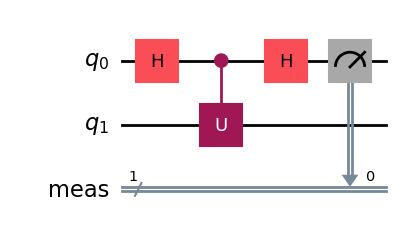

In [49]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
c_reg = ClassicalRegister(1, "meas")
q = QuantumRegister(2, r'q')


def evolution_gate():
    evol = QuantumCircuit(1)

    # state evolution
    evol.h(0)

    return evol.to_gate(label="U")


# Build the ansatz
qc = QuantumCircuit(q, c_reg)

qc.h(0)
#qc.sdg(0) # for imaginary part

U_gate = evolution_gate()
U_controlled_gate = U_gate.control(1)
qc.append(U_controlled_gate, [0, 1])
qc.h(0)
qc.measure(q[0], c_reg)

qc.draw('mpl')


## Ancilla interference

The first Hadamard prepares the ancilla in $|+\rangle=(|0\rangle+|1\rangle)/\sqrt{2}$. The controlled-$U$ gate creates

$$\frac{1}{\sqrt{2}}\left(|0\rangle|\psi\rangle+|1\rangle U|\psi\rangle\right).$$

A second Hadamard makes the two branches interfere. Measuring the ancilla therefore reveals information about their overlap. The optional phase gate changes the measured quadrature and is used for the imaginary part.

## Estimating the overlap

For the real-part circuit, the ancilla probabilities satisfy

$$p(0)-p(1)=\mathrm{Re}\left(\langle\psi|U|\psi\rangle\right).$$

The code estimates this difference from sampled counts. Squaring the result gives a fidelity-like quantity only when the overlap is real; in general, $|\langle\psi|U|\psi\rangle|^2$ requires both real and imaginary components.

In [51]:
from qiskit.primitives import StatevectorSampler

n_shots = 1000000
sampler = StatevectorSampler()
result = sampler.run([qc], shots=n_shots).result()
counts = result[0].data.meas.get_counts()
print(counts)
overlap = (counts['0'] - counts['1'])/n_shots
print(overlap, overlap**2)


{'0': 854201, '1': 145799}
0.708402 0.5018333936039999


- Substitute the H gate in the evolution gate by a $Ry(\theta)$ gate
- Compute the overlap as a function of $\theta$